In [1]:
#2024.7.23最新模拟，
#以单个细胞为单位，模拟2C发育到4C，用上所有通过QC的数据
#2代表 α，1代表 β，0代表 Undefined
#IVF模拟
import random
import time

def simulate_cell_division(cells, p1, p2, p3, p4,p5,p7,p8,p9,p10,p11,p13,p14,p15,p16,p17):
    cells_4 = []
    for cell in cells:
        rand_num_1 = random.random()
        
        if cell == [2]:
            if rand_num_1 < p1:
                pre_4 =[2, 2]
            elif rand_num_1 < p1 + p2:
                pre_4 =[2, 1]
            elif rand_num_1 < p1 + p2 + p3:
                pre_4 =[1, 1]
            elif rand_num_1 < p1 + p2 + p3 + p4:
                pre_4 =[2, 0]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
        elif cell == [1]:
            if rand_num_1 < p1:
                pre_4 =[2, 2]
            elif rand_num_1 < p1 + p2:
                pre_4 =[2, 1]
            elif rand_num_1 < p1 + p2 + p3:
                pre_4 =[1, 1]
            elif rand_num_1 < p1 + p2 + p3 + p4:
                pre_4 =[2, 0]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
        elif cell == [0]:
            if rand_num_1 < p7:
                pre_4 =[2, 2]
            elif rand_num_1 < p7 + p8:
                pre_4 =[2, 1]
            elif rand_num_1 < p7 + p8 + p9:
                pre_4 =[1, 1]
            elif rand_num_1 < p7 + p8 + p9 + p10:
                pre_4 =[2, 0]
            elif rand_num_1 < p7 + p8 + p9 + p10 + p11:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
    return cells_4

def count_combinations_4_cells(cells_4):
    count_c1 = 0
    count_c2 = 0
    count_un = 0

    total_count = len(cells_4) * 2

    for cell in cells_4:
        if cell.count(2) == 2:
            count_c1 += 2
        elif cell.count(2) == 1 and cell.count(1) == 1:
            count_c1 += 1
            count_c2 += 1
        elif cell.count(1) == 2:
            count_c2 += 2
        elif cell.count(2) == 1 and cell.count(0) == 1:
            count_c1 += 1
            count_un += 1
        elif cell.count(1) == 1 and cell.count(0) == 1:
            count_c2 += 1
            count_un += 1
        elif cell.count(0) == 2:
            count_un += 2
            
    probability_c1 = count_c1 / total_count
    probability_c2 = count_c2 / total_count
    probability_un = count_un / total_count

    return (
        probability_c1,
        probability_c2,
        probability_un
    )

def count_elements(lst):
    # Flatten the list
    flat_list = [item for sublist in lst for item in sublist]
    
    count_c1 = flat_list.count(2)
    count_c2 = flat_list.count(1)
    count_un = flat_list.count(0)
    
    total_count = count_c1 + count_c2 + count_un
    
    if total_count == 0:
        raise ValueError("The total count of elements is zero, cannot calculate probabilities.")
    
    probability_c1 = count_c1 / total_count
    probability_c2 = count_c2 / total_count
    probability_un = count_un / total_count
    
    return probability_c1, probability_c2, probability_un


def evaluate_difference(observed_probabilities, simulated_probabilities):
    difference = sum(abs(obs_prob - sim_prob) for obs_prob, sim_prob in zip(observed_probabilities, simulated_probabilities))
    return difference

def generate_positive_numbers(num_variables):
    # 生成 num_variables 个介于 0 到 1 之间的随机数
    numbers = [random.random() for _ in range(num_variables)]

    # 计算累加之和
    total_sum = sum(numbers)

    # 归一化，使得累加之和等于1
    normalized_numbers = [num / total_sum for num in numbers]

    return normalized_numbers


# 基于真实2细胞数据，等比例生成1000个细胞
cells_2 = [[2] for _ in range(550)] + [[1] for _ in range(440)] + [[0] for _ in range(10)]
#真实的4C比例，包括所有4C
true_lists = [[2] for _ in range(466)] + [[1] for _ in range(500)] + [[0] for _ in range(34)]

true_probabilities = count_elements(true_lists)
print(true_probabilities)


(0.466, 0.5, 0.034)


In [2]:
#IVF 模拟
import random
import numpy as np
from deap import base, creator, tools, algorithms
import matplotlib.pyplot as plt
import time

def evaluate_difference(observed_probabilities, simulated_probabilities):
    difference = sum(abs(obs_prob - sim_prob) for obs_prob, sim_prob in zip(observed_probabilities, simulated_probabilities))
    return difference

# 定义适应度评估函数
def evaluate_individual(individual):
    p1, p2, p3, p4,p5,p6,p7,p8,p9,p10,p11,p12,p13,p14,p15,p16,p17,p18 = individual
    sum1 = p1+p2+p3+p4+p5+p6
    sum2 = p7+p8+p9+p10+p11+p12
    sum3 = p13+p14+p15+p16+p17+p18
    p1 = p1/sum1
    p2 = p2/sum1
    p3 = p3/sum1
    p4 = p4/sum1
    p5 = p5/sum1
    p6 = p6/sum1
    p7 = p7/sum2
    p8 = p8/sum2
    p9 = p9/sum2
    p10 = p10/sum2
    p11 = p11/sum2
    p12 = p12/sum2
    p13 = p13/sum3
    p14 = p14/sum3
    p15 = p15/sum3
    p16 = p16/sum3
    p17 = p17/sum3
    p18 = p18/sum3
    # 如果任意一个参数小于0，则直接返回一个非常大的适应度值
    if any(p < 0 for p in [p1, p2, p3, p4, p5, p6, p7, p8, p9, p10, p11, p12, p13, p14, p15, p16, p17, p18]):
        difference=10
        return difference,
    else:
        simulated_cells_4 = simulate_cell_division(cells_2, p1, p2, p3, p4,p5,p7,p8,p9,p10,p11,p13,p14,p15,p16,p17)
        simulated_probabilities = count_combinations_4_cells(simulated_cells_4)
        difference = evaluate_difference(true_probabilities, simulated_probabilities)
        return difference,

# 定义遗传算法相关参数
population_size = 3200
num_generations = 200
num_parents = 1600
num_offspring = population_size - num_parents
num_repeats = 60

# 创建遗传算法工具箱
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))  # 通过使用负数的weights，我们可以建立最小化适应值的优化过程
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
toolbox.register("attr_float", random.uniform, 0, 1)  # 参数取值范围为[0, 1]
toolbox.register("individual", tools.initRepeat, creator.Individual, lambda: abs(random.uniform(0, 1)), n=18)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("evaluate", evaluate_individual)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=1, indpb=0.1)
toolbox.register("select", tools.selTournament, tournsize=3)

simulated_results = []  # 存储模拟结果
best_p_values = []  # 存储最佳p值

# 创建一个新的子图
#plt.figure(figsize=(5, 20))
best_fitnesses = []  # 存储每次迭代的最佳适应度值
# 迭代运行多次
for repeat in range(num_repeats):
    print(f"Repeat {repeat + 1}:")
    start_time = time.time()  # 记录模拟开始时间
    
    # 初始化种群
    population = toolbox.population(n=population_size)
    
    # 迭代演化
    for generation in range(num_generations):
        offspring = []
        
        # 通过选择父代个体、交叉操作和变异操作来生成指定数量的子代个体，并将其保存在子代列表中，以备后续的适应度评估和种群更新使用
        for _ in range(num_offspring):
            parent1 = random.choice(population)
            parent2 = random.choice(population)
            child = toolbox.clone(parent1)
            toolbox.mate(child, parent2)
            toolbox.mutate(child)
            offspring.append(child)
        
        # 评估子代适应度评，并将适应度值赋给相应的个体对象，以便进行后续的遗传算法操作。
        fitnesses = map(toolbox.evaluate, offspring)
        #print(toolbox.evaluate)
        for ind, fit in zip(offspring, fitnesses):
            ind.fitness.values = fit
        
        # 更新种群
        population = toolbox.select(population + offspring, k=population_size)
        # 存储每次迭代的最佳适应度值
        best_fitness = tools.selBest(population, k=1)[0].fitness.values[0]
        best_fitnesses.append(best_fitness) 
        
    # 获取最优解
    best_individual = tools.selBest(population, k=1)[0]
    best_p1, best_p2, best_p3, best_p4 , best_p5, best_p6, best_p7, best_p8, best_p9, best_p10, best_p11, best_p12, best_p13, best_p14, best_p15, best_p16, best_p17, best_p18= best_individual
    sum1 = best_p1+best_p2+best_p3+best_p4+best_p5+best_p6
    sum2 = best_p7+best_p8+best_p9+best_p10+best_p11+best_p12
    sum3 = best_p13+best_p14+best_p15+best_p16+best_p17+best_p18
    best_p1 = best_p1/sum1
    best_p2 = best_p2/sum1
    best_p3 = best_p3/sum1
    best_p4 = best_p4/sum1
    best_p5 = best_p5/sum1
    best_p6 = best_p6/sum1
    best_p7 = best_p7/sum2
    best_p8 = best_p8/sum2
    best_p9 = best_p9/sum2
    best_p10 = best_p10/sum2
    best_p11 = best_p11/sum2
    best_p12 = best_p12/sum2
    best_p13 = best_p13/sum3
    best_p14 = best_p14/sum3
    best_p15 = best_p15/sum3
    best_p16 = best_p16/sum3
    best_p17 = best_p17/sum3
    best_p18 = best_p18/sum3
    
    # 打印结果
    print("最佳p值:", best_p1, best_p2, best_p3, best_p4 , best_p5, best_p6, best_p7, best_p8, best_p9, best_p10, best_p11, best_p12, best_p13, best_p14, best_p15, best_p16, best_p17, best_p18)
    simulated_cells_4 = simulate_cell_division(cells_2, best_p1, best_p2, best_p3, best_p4,best_p5,best_p7,best_p8,best_p9,best_p10,best_p11,best_p13,best_p14,best_p15,best_p16,best_p17)
    simulated_probabilities = count_combinations_4_cells(simulated_cells_4)
    print("模拟结果:", simulated_probabilities)
    print("适应度:", tools.selBest(population, k=1)[0].fitness.values[0])
    print("diff:", evaluate_difference(true_probabilities, simulated_probabilities))
    
    end_time = time.time()  # 记录模拟结束时间
    elapsed_time = end_time - start_time  # 计算模拟运行时间
    elapsed_time_minutes = elapsed_time / 60  # 转换为分钟
    print("模拟用时", repeat + 1, ":", elapsed_time_minutes, "分钟")
    # 存储模拟结果和最佳p值
    simulated_results.append(simulated_probabilities)
    best_p_values.append([best_p1, best_p2, best_p3, best_p4])
    
    ## 绘制每次迭代的最佳适应度值变化曲线
    #plt.subplot(6, 1, repeat+1)  # 创建子图
    #best_fitnesses = [tools.selBest(population, k=1)[0].fitness.values[0] for population in populations]
    #plt.plot(range(num_generations), best_fitnesses, marker='o')
    #plt.xlabel('Generation')
    #plt.ylabel('Best Fitness')
    #plt.ylim(0, 0.2)  # 设置y轴范围
    #plt.title(f'Repeat {repeat+1}')
    #plt.grid(True)
    # 重置best_fitnesses列表，以便进行下一次迭代
    best_fitnesses = []


Repeat 1:
最佳p值: 0.13496337916422446 0.6528717142680912 0.15250786790286347 0.004977612792406964 0.04985040544359235 0.004829020428821471 0.19771827548025478 0.09996610582300454 0.16625255784365436 0.07707960085061223 0.2125983610873189 0.24638509891515517 0.04944152366560201 0.033412815922769214 0.09126736321080223 0.5098756142560423 0.05163607981599888 0.2643666031287853
模拟结果: (0.4785, 0.49, 0.0315)
适应度: 0.0
diff: 0.024999999999999967
模拟用时 1 : 12.702440134684245 分钟
Repeat 2:
最佳p值: 0.07325799824778308 0.7871957012759325 0.10147197537616562 0.008880598814479028 0.013781886489244027 0.015411839796395738 0.13202356175865654 0.06884058681875752 0.003304548129513363 0.4344514758317763 0.11994894597355006 0.24143088148774625 0.05532352801646421 0.18226378508929064 0.3362514422510931 0.2255192353873343 0.16249203385492547 0.038149975400892204
模拟结果: (0.48, 0.487, 0.033)
适应度: 0.0
diff: 0.02799999999999997
模拟用时 2 : 10.969505417346955 分钟
Repeat 3:
最佳p值: 0.07422215973570379 0.7786201964784045 0.10

最佳p值: 0.07738743323670834 0.7639373156112881 0.10705478249834154 0.018365667700480683 0.023099270811988856 0.01015553014119248 0.19455478933462494 0.1543087231420562 0.06441710467081434 0.22246896441976868 0.18815793302854766 0.17609248540418818 0.12359308926724547 0.0233809599326784 0.09671501808700286 0.49882950569293055 0.0944102790576642 0.16307114796247857
模拟结果: (0.4625, 0.503, 0.0345)
适应度: 0.0
diff: 0.007000000000000006
模拟用时 19 : 13.255353446801504 分钟
Repeat 20:
最佳p值: 0.06621339758314677 0.7638870388405711 0.10315740429385091 0.04732112733371215 0.01852538553685732 0.000895646411861732 0.09050561349630734 0.37363298701189723 0.10073132015030163 0.20313256569917126 0.14991147569856175 0.08208603794376076 0.3196828350362839 0.022235643670475213 0.039160669699477235 0.23436069260461664 0.15896980701463187 0.2255903519745151
模拟结果: (0.4665, 0.5065, 0.027)
适应度: 0.0
diff: 0.013999999999999953
模拟用时 20 : 10.531594045956929 分钟
Repeat 21:
最佳p值: 0.08060111791959979 0.7490977747674076 0.11169

最佳p值: 0.15812456612534687 0.6038206276612046 0.19013633069702807 0.033809768638000226 0.00866484963849512 0.00544385723992519 0.15001326611290547 0.21982811496712618 0.05132585776317394 0.3736652452561232 0.17833634127222506 0.026831174628446197 0.06696298704687723 0.31834438517505753 0.22423850144877566 0.1328987845241657 0.10250144818658662 0.15505389361853736
模拟结果: (0.464, 0.5035, 0.0325)
适应度: 0.0
diff: 0.006999999999999951
模拟用时 37 : 10.912019085884094 分钟
Repeat 38:
最佳p值: 0.05378084498782891 0.7800568434625594 0.0949888860114866 0.038173358500792745 0.03133798951191547 0.0016620775254166686 0.16786046869823995 0.2237265813083278 0.27325047885804765 0.18079633142576534 0.024810775938880276 0.12955536377073898 0.1918854850960213 0.09317658053821395 0.30349800531366206 0.0739050829314099 0.15436317110685988 0.18317167501383277
模拟结果: (0.4655, 0.501, 0.0335)
适应度: 0.0
diff: 0.0020000000000000018
模拟用时 38 : 12.284384767214457 分钟
Repeat 39:
最佳p值: 0.05471454479711193 0.8159295068301606 0.0765

最佳p值: 0.15568042225505765 0.6286135744542277 0.16065316496933704 0.0039053965843004164 0.05111111297673131 3.6328760346000586e-05 0.15111803334393395 0.3098559567991543 0.1397349267107489 0.1282435733941475 0.20278980926894632 0.06825770048306898 0.21432084060483933 0.09698758227191273 0.23404488681965066 0.042995330538655174 0.21479976456592545 0.1968515951990167
模拟结果: (0.4755, 0.495, 0.0295)
适应度: 0.0
diff: 0.01899999999999996
模拟用时 55 : 2.574857739607493 分钟
Repeat 56:
最佳p值: 0.06801474830247102 0.7971314989689371 0.07779346856309412 0.011359921744101345 0.03294726100816558 0.01275310141323084 0.12461752622389217 0.026341953338320484 0.2468466701384005 0.23168489815335735 0.06011395695720629 0.31039499518882324 0.17145253468272642 0.5049228840300358 0.18787228124524408 0.08830800628249026 0.023443482448129847 0.024000811311373514
模拟结果: (0.464, 0.5005, 0.0355)
适应度: 0.0
diff: 0.003999999999999941
模拟用时 56 : 2.564426259199778 分钟
Repeat 57:
最佳p值: 0.07412689027121179 0.7768375241893277 0.0964

In [1]:
#2025.9.29最新模拟，
#以单个细胞为单位，模拟2C发育到4C，用上所有数据，包括通过和没通过QC的细胞
#3代表 α，2代表 β，1代表 Undefined，0代表 failedQC 
#IVF模拟
import random
import time

def simulate_cell_division(cells, p1, p2, p3, p4, p5, p6, p7, p8, p9, p10, p11, p12, p13, p14, p15, p16, p17, p18, p19, p20, p21, p22, p23, p24, p25, p26, p27, p28, p29, p30, p31, p32, p33, p34, p35, p36, p37, p38, p39, p40):
    cells_4 = []
    for cell in cells:
        rand_num_1 = random.random()
        
        if cell == [3]:
            if rand_num_1 < p1:
                pre_4 =[3, 3]
            elif rand_num_1 < p1 + p2:
                pre_4 =[3, 2]
            elif rand_num_1 < p1 + p2 + p3:
                pre_4 =[2, 2]
            elif rand_num_1 < p1 + p2 + p3 + p4:
                pre_4 =[3, 1]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5:
                pre_4 =[3, 0]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5+p6:
                pre_4 =[2, 1]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5+p6+p7:
                pre_4 =[2, 0]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5+p6+p7+p8:
                pre_4 =[1, 1]
            elif rand_num_1 < p1 + p2 + p3 + p4 +p5+p6+p7+p8+p9:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
        elif cell == [2]:
            if rand_num_1 < p11:
                pre_4 =[3, 3]
            elif rand_num_1 < p11 + p12:
                pre_4 =[3, 2]
            elif rand_num_1 < p11 + p12 + p13:
                pre_4 =[2, 2]
            elif rand_num_1 < p11 + p12 + p13 + p14:
                pre_4 =[3, 1]
            elif rand_num_1 < p11 + p12 + p13 + p14 +p15:
                pre_4 =[3, 0]
            elif rand_num_1 < p11 + p12 + p13 + p14 +p15+p16:
                pre_4 =[2, 1]
            elif rand_num_1 < p11 + p12 + p13 + p14 +p15+p16+p17:
                pre_4 =[2, 0]
            elif rand_num_1 < p11 + p12 + p13 + p14 +p15+p16+p17+p18:
                pre_4 =[1, 1]
            elif rand_num_1 < p11 + p12 + p13 + p14 +p15+p16+p17+p18+p19:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
        elif cell == [1]:
            if rand_num_1 < p21:
                pre_4 =[3, 3]
            elif rand_num_1 < p21 + p22:
                pre_4 =[3, 2]
            elif rand_num_1 < p21 + p22 + p23:
                pre_4 =[2, 2]
            elif rand_num_1 < p21 + p22 + p23 + p24:
                pre_4 =[3, 1]
            elif rand_num_1 < p21 + p22 + p23 + p24 +p25:
                pre_4 =[3, 0]
            elif rand_num_1 < p21 + p22 + p23 + p24 +p25+p26:
                pre_4 =[2, 1]
            elif rand_num_1 < p21 + p22 + p23 + p24 +p25+p26+p27:
                pre_4 =[2, 0]
            elif rand_num_1 < p21 + p22 + p23 + p24 +p25+p26+p27+p28:
                pre_4 =[1, 1]
            elif rand_num_1 < p21 + p22 + p23 + p24 +p25+p26+p27+p28+p29:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
        elif cell == [0]:
            if rand_num_1 < p31:
                pre_4 =[3, 3]
            elif rand_num_1 < p31 + p32:
                pre_4 =[3, 2]
            elif rand_num_1 < p31 + p32 + p33:
                pre_4 =[2, 2]
            elif rand_num_1 < p31 + p32 + p33 + p34:
                pre_4 =[3, 1]
            elif rand_num_1 < p31 + p32 + p33 + p34 +p35:
                pre_4 =[3, 0]
            elif rand_num_1 < p31 + p32 + p33 + p34 +p35+p36:
                pre_4 =[2, 1]
            elif rand_num_1 < p31 + p32 + p33 + p34 +p35+p36+p37:
                pre_4 =[2, 0]
            elif rand_num_1 < p31 + p32 + p33 + p34 +p35+p36+p37+p38:
                pre_4 =[1, 1]
            elif rand_num_1 < p31 + p32 + p33 + p34 +p35+p36+p37+p38+p39:
                pre_4 =[1, 0]
            else:
                pre_4 =[0, 0]
                
            c4=pre_4
            cells_4.append(c4)
            
    return cells_4

def count_combinations_4_cells(cells_4):
    count_c1 = 0
    count_c2 = 0
    count_un = 0
    count_fqc = 0

    total_count = len(cells_4) * 2

    for cell in cells_4:
        if cell.count(3) == 2: 
            count_c1 += 2
        elif cell.count(3) == 1 and cell.count(2) == 1:
            count_c1 += 1
            count_c2 += 1
        elif cell.count(3) == 1 and cell.count(1) == 1:
            count_c1 += 1
            count_un += 1
        elif cell.count(3) == 1 and cell.count(0) == 1:
            count_c1 += 1
            count_fqc += 1
        elif cell.count(2) == 2:
            count_c2 += 2
        elif cell.count(2) == 1 and cell.count(1) == 1:
            count_c2 += 1
            count_un += 1
        elif cell.count(2) == 1 and cell.count(0) == 1:
            count_c2 += 1
            count_fqc += 1
        elif cell.count(1) == 2:
            count_un += 2
        elif cell.count(1) == 1 and cell.count(0) == 1:
            count_un += 1
            count_fqc += 1
        elif cell.count(0) == 2:
            count_fqc += 2
            
    probability_c1 = count_c1 / total_count
    probability_c2 = count_c2 / total_count
    probability_un = count_un / total_count
    probability_fqc = count_fqc / total_count

    return (
        probability_c1,
        probability_c2,
        probability_un,
        probability_fqc
    )

def count_elements(lst):
    # Flatten the list
    flat_list = [item for sublist in lst for item in sublist]
    
    count_c1 = flat_list.count(3)
    count_c2 = flat_list.count(2)
    count_un = flat_list.count(1)
    count_fqc = flat_list.count(0)
    
    total_count = count_c1 + count_c2 + count_un+count_fqc
    
    if total_count == 0:
        raise ValueError("The total count of elements is zero, cannot calculate probabilities.")
    
    probability_c1 = count_c1 / total_count
    probability_c2 = count_c2 / total_count
    probability_un = count_un / total_count
    probability_fqc = count_fqc / total_count
    
    return probability_c1, probability_c2, probability_un,probability_fqc


def evaluate_difference(observed_probabilities, simulated_probabilities):
    difference = sum(abs(obs_prob - sim_prob) for obs_prob, sim_prob in zip(observed_probabilities, simulated_probabilities))
    return difference

def generate_positive_numbers(num_variables):
    # 生成 num_variables 个介于 0 到 1 之间的随机数
    numbers = [random.random() for _ in range(num_variables)]

    # 计算累加之和
    total_sum = sum(numbers)

    # 归一化，使得累加之和等于1
    normalized_numbers = [num / total_sum for num in numbers]

    return normalized_numbers

# 基于真实2细胞数据，等比例生成1000个细胞
# 3代表 H1，2代表 H2，1代表 Undefined，0代表 failedQC 
cells_2 = [[3] for _ in range(352)]+[[2] for _ in range(192)] + [[1] for _ in range(11)] + [[0] for _ in range(445)]
#真实的4C比例，包括所有4C
true_lists = [[3] for _ in range(470)]+[[2] for _ in range(218)] + [[1] for _ in range(42)] + [[0] for _ in range(270)]

true_probabilities = count_elements(true_lists)
print(true_probabilities)


(0.47, 0.218, 0.042, 0.27)


In [ ]:
#以单个细胞为单位，模拟2C发育到4C，用上所有数据，包括通过和没通过QC的细胞
#3代表 H1，2代表 H2，1代表 Undefined，0代表 failedQC 
#IVF模拟
import random
import numpy as np
from deap import base, creator, tools, algorithms
import matplotlib.pyplot as plt
import time

def custom_mutate(individual, mu=0, sigma=1, indpb=0.1):
    for i in range(len(individual)):
        if random.random() < indpb:
            individual[i] += random.gauss(mu, sigma)
            individual[i] = abs(individual[i])
            
def evaluate_difference(observed_probabilities, simulated_probabilities):
    difference = sum(abs(obs_prob - sim_prob) for obs_prob, sim_prob in zip(observed_probabilities, simulated_probabilities))
    return difference

# 定义适应度评估函数
def evaluate_individual(individual):
            
    p1, p2, p3, p4, p5, p6, p7, p8, p9, p10,p11, p12, p13, p14, p15, p16, p17, p18, p19, p20,p21, p22, p23, p24, p25, p26, p27, p28, p29, p30,p31, p32, p33, p34, p35, p36, p37, p38, p39, p40 = individual
    sum1 = p1+ p2+ p3+ p4+ p5+ p6+ p7+ p8+ p9+ p10
    sum2 = p11+ p12+ p13+ p14+ p15+ p16+ p17+ p18+ p19+ p20
    sum3 = p21+ p22+ p23+ p24+ p25+ p26+ p27+ p28+ p29+ p30
    sum4 = p31+ p32+ p33+ p34+ p35+ p36+ p37+ p38+ p39+ p40
    p1 = p1 / sum1
    p2 = p2 / sum1
    p3 = p3 / sum1
    p4 = p4 / sum1
    p5 = p5 / sum1
    p6 = p6 / sum1
    p7 = p7 / sum1
    p8 = p8 / sum1
    p9 = p9 / sum1
    p10 = p10 / sum1
    p11 = p11 / sum2
    p12 = p12 / sum2
    p13 = p13 / sum2
    p14 = p14 / sum2
    p15 = p15 / sum2
    p16 = p16 / sum2
    p17 = p17 / sum2
    p18 = p18 / sum2
    p19 = p19 / sum2
    p20 = p20 / sum2
    p21 = p21 / sum3
    p22 = p22 / sum3
    p23 = p23 / sum3
    p24 = p24 / sum3
    p25 = p25 / sum3
    p26 = p26 / sum3
    p27 = p27 / sum3
    p28 = p28 / sum3
    p29 = p29 / sum3
    p30 = p30 / sum3
    p31 = p31 / sum4
    p32 = p32 / sum4
    p33 = p33 / sum4
    p34 = p34 / sum4
    p35 = p35 / sum4
    p36 = p36 / sum4
    p37 = p37 / sum4
    p38 = p38 / sum4
    p39 = p39 / sum4
    p40 = p40 / sum4

    #明天从这里继续修改
    
    # 如果任意一个参数小于0，则直接返回一个非常大的适应度值
    if any(p < 0 for p in [p1, p2, p3, p4, p5, p6, p7, p8, p9, p10,p11, p12, p13, p14, p15, p16, p17, p18, p19, p20,p21, p22, p23, p24, p25, p26, p27, p28, p29, p30,p31, p32, p33, p34, p35, p36, p37, p38, p39, p40]):
        difference=10
        return difference,
    else:
        simulated_cells_4 = simulate_cell_division(cells_2, p1, p2, p3, p4, p5, p6, p7, p8, p9, p10,p11, p12, p13, p14, p15, p16, p17, p18, p19, p20,p21, p22, p23, p24, p25, p26, p27, p28, p29, p30,p31, p32, p33, p34, p35, p36, p37, p38, p39, p40)
        simulated_probabilities = count_combinations_4_cells(simulated_cells_4)
        difference = evaluate_difference(true_probabilities, simulated_probabilities)
        return difference,

# 定义遗传算法相关参数
population_size = 3200
num_generations = 200
num_parents = 1600
num_offspring = population_size - num_parents
num_repeats = 100

# 创建遗传算法工具箱
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))  # 通过使用负数的weights，我们可以建立最小化适应值的优化过程
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
toolbox.register("attr_float", random.uniform, 0, 1)  # 参数取值范围为[0, 1]
toolbox.register("individual", tools.initRepeat, creator.Individual, lambda: abs(random.uniform(0, 1)), n=40)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("evaluate", evaluate_individual)
toolbox.register("mate", tools.cxTwoPoint)
#原始的突变，可能会突变出负数
#toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=1, indpb=0.1)
toolbox.register("mutate", custom_mutate, mu=0, sigma=1, indpb=0.1)
toolbox.register("select", tools.selTournament, tournsize=3)

simulated_results = []  # 存储模拟结果
best_p_values = []  # 存储最佳p值

# 创建一个新的子图
#plt.figure(figsize=(5, 20))
best_fitnesses = []  # 存储每次迭代的最佳适应度值
# 迭代运行多次
for repeat in range(num_repeats):
    print(f"Repeat {repeat + 1}:")
    start_time = time.time()  # 记录模拟开始时间
    
    # 初始化种群
    population = toolbox.population(n=population_size)
    
    # 迭代演化
    for generation in range(num_generations):
        offspring = []
        
        # 通过选择父代个体、交叉操作和变异操作来生成指定数量的子代个体，并将其保存在子代列表中，以备后续的适应度评估和种群更新使用
        for _ in range(num_offspring):
            parent1 = random.choice(population)
            parent2 = random.choice(population)
            child = toolbox.clone(parent1)
            toolbox.mate(child, parent2)
            toolbox.mutate(child)
            #child = [abs(x) for x in child]#突变后会产生负数，将负数替换为其相反数
            offspring.append(child)
        
        # 评估子代适应度评，并将适应度值赋给相应的个体对象，以便进行后续的遗传算法操作。
        fitnesses = map(toolbox.evaluate, offspring)
        #print(toolbox.evaluate)
        for ind, fit in zip(offspring, fitnesses):
            ind.fitness.values = fit
        
        # 更新种群
        population = toolbox.select(population + offspring, k=population_size)
        # 存储每次迭代的最佳适应度值
        best_fitness = tools.selBest(population, k=1)[0].fitness.values[0]
        best_fitnesses.append(best_fitness) 
        
    # 获取最优解
    best_individual = tools.selBest(population, k=1)[0]
    best_p1, best_p2, best_p3, best_p4, best_p5, best_p6, best_p7, best_p8, best_p9, best_p10, best_p11, best_p12, best_p13, best_p14, best_p15, best_p16, best_p17, best_p18, best_p19, best_p20, best_p21, best_p22, best_p23, best_p24, best_p25, best_p26, best_p27, best_p28, best_p29, best_p30, best_p31, best_p32, best_p33, best_p34, best_p35, best_p36, best_p37, best_p38, best_p39, best_p40= best_individual
    
    sum1 = best_p1 + best_p2 + best_p3 + best_p4 + best_p5 + best_p6 + best_p7 + best_p8 + best_p9 + best_p10
    sum2 = best_p11 + best_p12 + best_p13 + best_p14 + best_p15 + best_p16 + best_p17 + best_p18 + best_p19 + best_p20
    sum3 = best_p21 + best_p22 + best_p23 + best_p24 + best_p25 + best_p26 + best_p27 + best_p28 + best_p29 + best_p30
    sum4 = best_p31 + best_p32 + best_p33 + best_p34 + best_p35 + best_p36 + best_p37 + best_p38 + best_p39 + best_p40

    best_p1 = best_p1 / sum1
    best_p2 = best_p2 / sum1
    best_p3 = best_p3 / sum1
    best_p4 = best_p4 / sum1
    best_p5 = best_p5 / sum1
    best_p6 = best_p6 / sum1
    best_p7 = best_p7 / sum1
    best_p8 = best_p8 / sum1
    best_p9 = best_p9 / sum1
    best_p10 = best_p10 / sum1
    best_p11 = best_p11 / sum2
    best_p12 = best_p12 / sum2
    best_p13 = best_p13 / sum2
    best_p14 = best_p14 / sum2
    best_p15 = best_p15 / sum2
    best_p16 = best_p16 / sum2
    best_p17 = best_p17 / sum2
    best_p18 = best_p18 / sum2
    best_p19 = best_p19 / sum2
    best_p20 = best_p20 / sum2
    best_p21 = best_p21 / sum3
    best_p22 = best_p22 / sum3
    best_p23 = best_p23 / sum3
    best_p24 = best_p24 / sum3
    best_p25 = best_p25 / sum3
    best_p26 = best_p26 / sum3
    best_p27 = best_p27 / sum3
    best_p28 = best_p28 / sum3
    best_p29 = best_p29 / sum3
    best_p30 = best_p30 / sum3
    best_p31 = best_p31 / sum4
    best_p32 = best_p32 / sum4
    best_p33 = best_p33 / sum4
    best_p34 = best_p34 / sum4
    best_p35 = best_p35 / sum4
    best_p36 = best_p36 / sum4
    best_p37 = best_p37 / sum4
    best_p38 = best_p38 / sum4
    best_p39 = best_p39 / sum4
    best_p40 = best_p40 / sum4

    # 打印结果
    print("最佳p值:", best_p1, best_p2, best_p3, best_p4, best_p5, best_p6, best_p7, best_p8, best_p9, best_p10, best_p11, best_p12, best_p13, best_p14, best_p15, best_p16, best_p17, best_p18, best_p19, best_p20, best_p21, best_p22, best_p23, best_p24, best_p25, best_p26, best_p27, best_p28, best_p29, best_p30, best_p31, best_p32, best_p33, best_p34, best_p35, best_p36, best_p37, best_p38, best_p39, best_p40)
    simulated_cells_4 = simulate_cell_division(cells_2, best_p1, best_p2, best_p3, best_p4, best_p5, best_p6, best_p7, best_p8, best_p9, best_p10, best_p11, best_p12, best_p13, best_p14, best_p15, best_p16, best_p17, best_p18, best_p19, best_p20, best_p21, best_p22, best_p23, best_p24, best_p25, best_p26, best_p27, best_p28, best_p29, best_p30, best_p31, best_p32, best_p33, best_p34, best_p35, best_p36, best_p37, best_p38, best_p39, best_p40)
    simulated_probabilities = count_combinations_4_cells(simulated_cells_4)
    print("模拟结果:", simulated_probabilities)
    print("适应度:", tools.selBest(population, k=1)[0].fitness.values[0])
    print("diff:", evaluate_difference(true_probabilities, simulated_probabilities))
    
    end_time = time.time()  # 记录模拟结束时间
    elapsed_time = end_time - start_time  # 计算模拟运行时间
    elapsed_time_minutes = elapsed_time / 60  # 转换为分钟
    print("模拟用时", repeat + 1, ":", elapsed_time_minutes, "分钟")
    # 存储模拟结果和最佳p值
    simulated_results.append(simulated_probabilities)
    best_p_values.append([best_p1, best_p2, best_p3, best_p4, best_p5, best_p6, best_p7, best_p8, best_p9, best_p10, best_p11, best_p12, best_p13, best_p14, best_p15, best_p16, best_p17, best_p18, best_p19, best_p20, best_p21, best_p22, best_p23, best_p24, best_p25, best_p26, best_p27, best_p28, best_p29, best_p30, best_p31, best_p32, best_p33, best_p34, best_p35, best_p36, best_p37, best_p38, best_p39, best_p40])
    
    best_fitnesses = []


Repeat 1:
最佳p值: 0.05178588298967114 0.28347377399020585 0.045375297226214056 0.00627712722987611 0.3917373224277297 0.05004506497407772 0.09750931964355426 0.008738276739519229 0.029789354253214752 0.035268580525937225 0.1269444216495323 0.3298914958272133 0.019281034072650843 0.06742223225045138 0.12010372447141614 0.02209010483354466 0.2436925445741348 0.05103990958456107 0.015878198255019856 0.0036563344814756786 0.29866813079325893 0.02751938283403767 0.1954724177196485 0.0677749781282679 0.11548669025240318 0.03691255492151048 0.06148747786713615 0.01743932131097417 0.04559188213655497 0.133647164036208 0.27772970332663194 0.15541715033741424 0.02613052504164183 0.011607459161399807 0.3902140556632448 0.012101896804635512 0.06522824592713557 0.009687581112613834 0.009384781874324266 0.042498600750958355
模拟结果: (0.467, 0.233, 0.0495, 0.2505)
适应度: 0.0010000000000000009
diff: 0.04499999999999998
模拟用时 1 : 8.61044324239095 分钟
Repeat 2:


Loading existing simulation data...
Data loaded successfully. Skipping simulation.


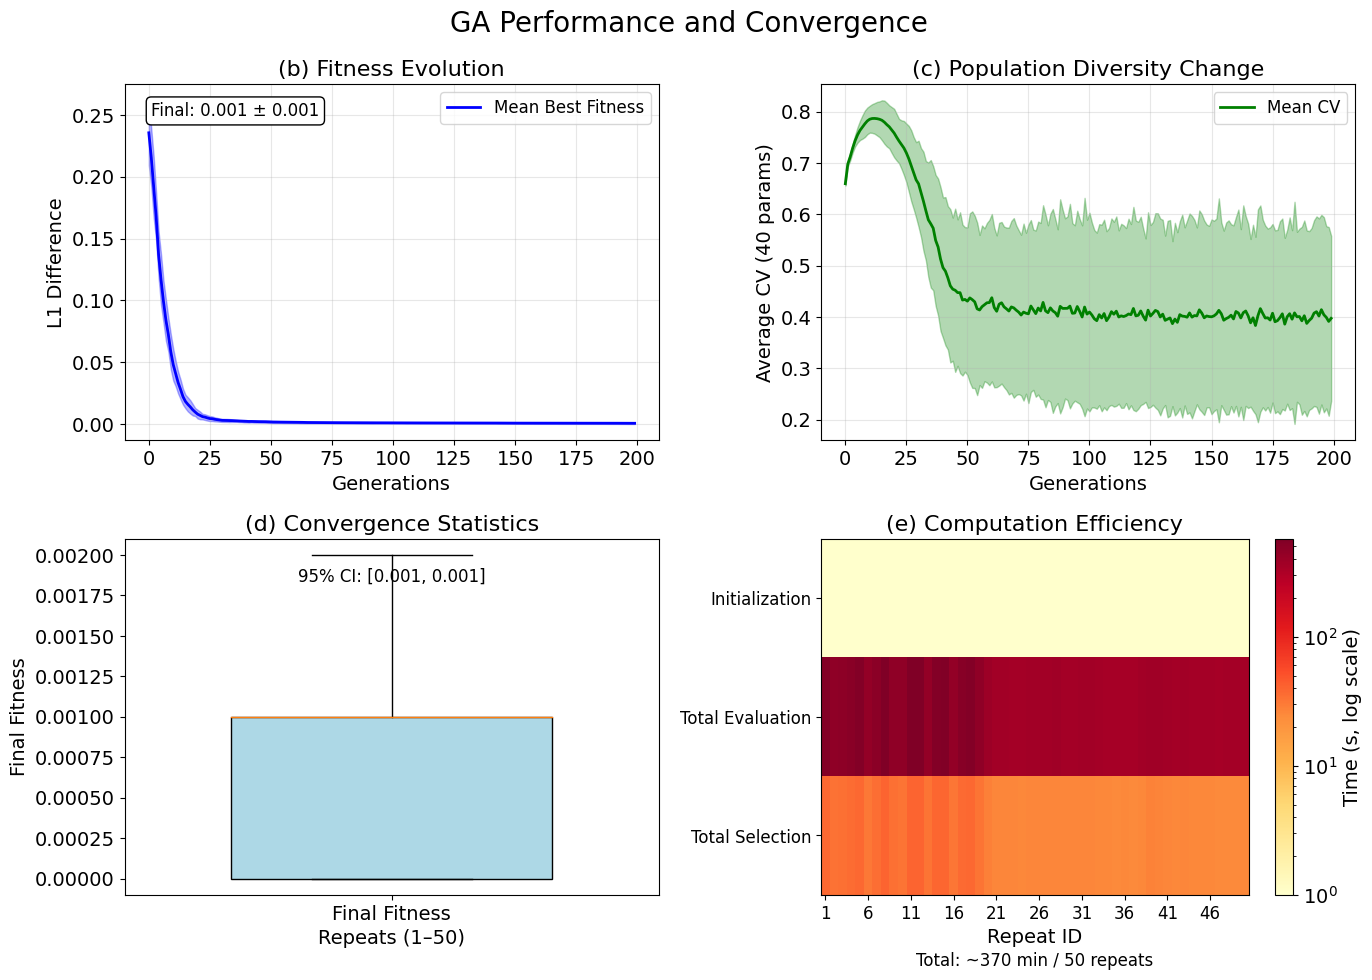

✅ Figure 1 (b–e) saved as figure1_bcde.png


In [10]:
# 只绘制(b)-(e)四个子图版本
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from deap import base, creator, tools, algorithms
import os
import pickle
from matplotlib.colors import LogNorm  # ✅

# ------------------------
# 数据加载
# ------------------------
data_file = '/home/lihaoxing/ga/ga_simulation_data.pkl'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['font.size'] = 14  # ✅ 全局字体放大

load_data = os.path.exists(data_file)

if load_data:
    print("Loading existing simulation data...")
    with open(data_file, 'rb') as f:
        saved_data = pickle.load(f)
    fitness_history = saved_data['fitness_history']
    diversity_history = saved_data['diversity_history']
    times_per_repeat = saved_data['times_per_repeat']
    simulated_results = saved_data['simulated_results']
    best_p_values = saved_data['best_p_values']
    print("Data loaded successfully. Skipping simulation.")
else:
    raise FileNotFoundError("❌ No saved data found. Need simulation first!")

# ------------------------
# 数据整理
# ------------------------
num_generations = 200
generations = np.arange(num_generations)

fitness_all = np.array(fitness_history)
diversity_all = np.array(diversity_history)
fitness_mean = np.mean(fitness_all, axis=0)
fitness_sd = np.std(fitness_all, axis=0)
diversity_mean = np.mean(diversity_all, axis=0)
diversity_sd = np.std(diversity_all, axis=0)
final_fitnesses = fitness_all[:, -1]

# 95% 置信区间
ci_low, ci_high = stats.t.interval(
    0.95, len(final_fitnesses)-1,
    loc=np.mean(final_fitnesses),
    scale=stats.sem(final_fitnesses)
)

# 效率数据
steps = ['Initialization', 'Total Evaluation', 'Total Selection']
efficiency_data = np.zeros((len(times_per_repeat), 3))
for r, tdict in enumerate(times_per_repeat):
    efficiency_data[r, 0] = tdict['init']
    efficiency_data[r, 1] = tdict['eval_total']
    efficiency_data[r, 2] = tdict['select_total'] + tdict['offspring_total']
total_time_min = np.sum(efficiency_data) / 60

# ------------------------
# 只画 b–e 四个图
# ------------------------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))  # ✅ 两行两列
(ax_b, ax_c), (ax_d, ax_e) = axs
fig.suptitle('GA Performance and Convergence', fontsize=20, y=0.98)

# (b) Fitness
ax_b.plot(generations, fitness_mean, 'b-', linewidth=2, label='Mean Best Fitness')
ax_b.fill_between(generations, fitness_mean - fitness_sd, fitness_mean + fitness_sd, alpha=0.3, color='blue')
ax_b.set_xlabel('Generations', fontsize=14)
ax_b.set_ylabel('L1 Difference', fontsize=14)
ax_b.set_title('(b) Fitness Evolution', fontsize=16)
ax_b.grid(True, alpha=0.3)
final_mean = np.mean(final_fitnesses)
final_sd = np.std(final_fitnesses)
ax_b.text(0.05, 0.95, f'Final: {final_mean:.3f} ± {final_sd:.3f}', transform=ax_b.transAxes,
          va='top', fontsize=12, bbox=dict(boxstyle='round', facecolor='white'))
ax_b.legend(fontsize=12)

# (c) Diversity
ax_c.plot(generations, diversity_mean, 'g-', linewidth=2, label='Mean CV')
ax_c.fill_between(generations, diversity_mean - diversity_sd, diversity_mean + diversity_sd, alpha=0.3, color='green')
ax_c.set_xlabel('Generations', fontsize=14)
ax_c.set_ylabel('Average CV (40 params)', fontsize=14)
ax_c.set_title('(c) Population Diversity Change', fontsize=16)
ax_c.grid(True, alpha=0.3)
ax_c.legend(fontsize=12)

# (d) Boxplot
bp = ax_d.boxplot(final_fitnesses, positions=[1], widths=0.6, patch_artist=True, labels=['Final Fitness'])
bp['boxes'][0].set_facecolor('lightblue')
ax_d.set_xlabel('Repeats (1–50)', fontsize=14)
ax_d.set_ylabel('Final Fitness', fontsize=14)
ax_d.set_title('(d) Convergence Statistics', fontsize=16)
ax_d.text(0.5, 0.92,  # x=0.5水平居中，y=0.92稍低于标题
          f'95% CI: [{ci_low:.3f}, {ci_high:.3f}]',
          transform=ax_d.transAxes,  # 相对坐标
          ha='center', va='top', fontsize=12)

# 标出异常值
q1, q3 = np.percentile(final_fitnesses, [25, 75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outliers_y = final_fitnesses[(final_fitnesses < lower_fence) | (final_fitnesses > upper_fence)]
if len(outliers_y) > 0:
    ax_d.scatter(np.ones(len(outliers_y)), outliers_y, color='red', s=30, zorder=5)

# (e) Heatmap
if np.max(efficiency_data) > 0:
    im = ax_e.imshow(efficiency_data.T, cmap='YlOrRd', aspect='auto',
                     norm=LogNorm(vmin=1, vmax=np.max(efficiency_data)))
else:
    im = ax_e.imshow(efficiency_data.T, cmap='YlOrRd', aspect='auto')
ax_e.set_xticks(np.arange(0, len(times_per_repeat), 5))
ax_e.set_xticklabels(np.arange(1, len(times_per_repeat)+1, 5), fontsize=12)
ax_e.set_yticks(np.arange(len(steps)))
ax_e.set_yticklabels(steps, fontsize=12)
ax_e.set_title('(e) Computation Efficiency', fontsize=16)
ax_e.set_xlabel('Repeat ID', fontsize=14)
cbar = plt.colorbar(im, ax=ax_e, label='Time (s, log scale)')
ax_e.text(0.5, -0.2, f'Total: ~{total_time_min:.0f} min / 50 repeats',
          transform=ax_e.transAxes, ha='center', fontsize=12)

plt.tight_layout()
plt.savefig('figure1_bcde.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 1 (b–e) saved as figure1_bcde.png")


In [30]:
import pandas as pd
import numpy as np

# best_p_array: shape = (50, 40)
# 每行是一次重复实验的最优 p 值（共40个参数）

# 构建 DataFrame
df_p = pd.DataFrame(best_p_array, columns=[f'p{i+1}' for i in range(40)])
df_p.index = [f'repeat_{i+1}' for i in range(len(best_p_array))]

# 保存为制表符分隔的文本文件
df_p.to_csv('best_p_values_50runs.txt', sep='\t', index=True)

print("✅ 已将50次最优p值写入文件：best_p_values_50runs.txt")


✅ 已将50次最优p值写入文件：best_p_values_50runs.txt


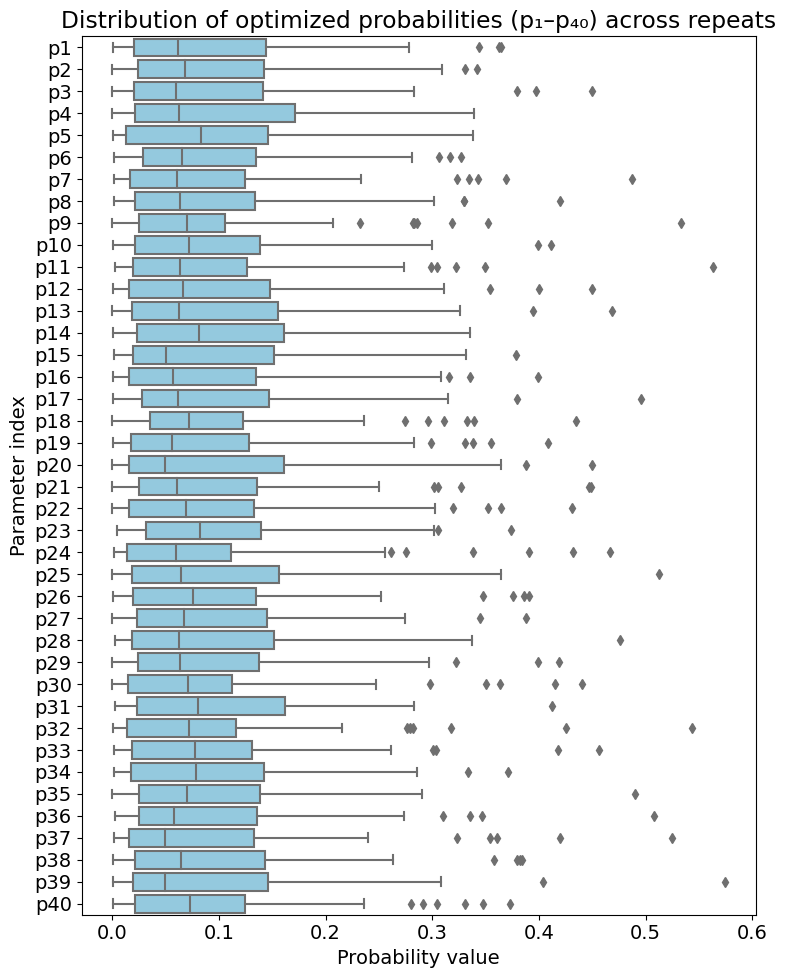

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

best_p_array = np.array(best_p_array)
df_p = pd.DataFrame(best_p_array, columns=[f'p{i+1}' for i in range(40)])

plt.figure(figsize=(8,10))
# 转置后每列一个参数
sns.boxplot(x=df_p.values.flatten(),
            y=np.repeat(df_p.columns, df_p.shape[0]),
            color='skyblue', orient='h')
plt.title('Distribution of optimized probabilities (p₁–p₄₀) across repeats')
plt.xlabel('Probability value')
plt.ylabel('Parameter index')
plt.tight_layout()
plt.savefig('figure2a_p_distribution.png', dpi=300)
plt.show()


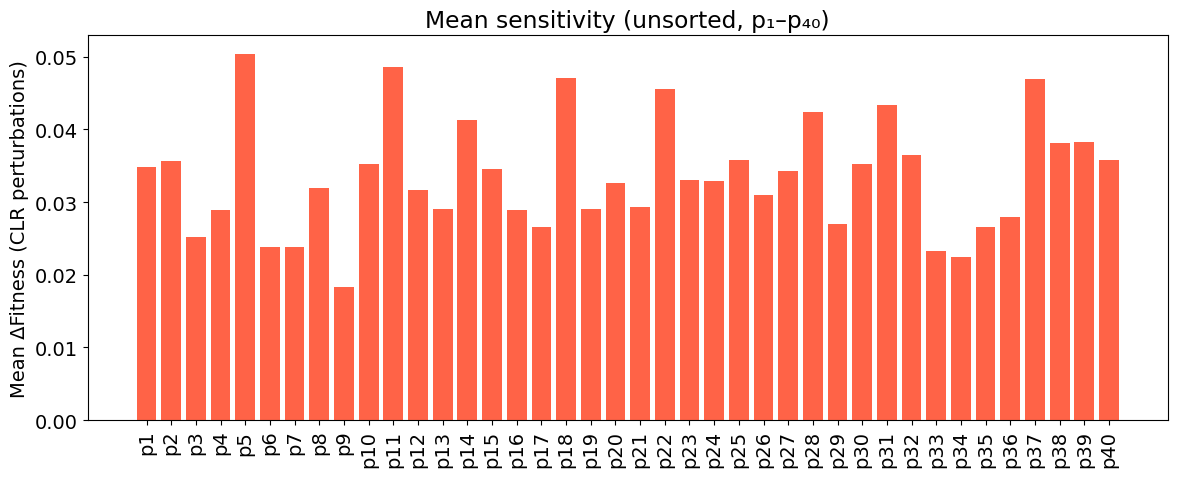


Top 10 most sensitive parameters (largest mean Δ):
Rank | Param | meanΔ | maxΔ
   1 | p5   | 0.050427 | 0.068260
   2 | p11  | 0.048593 | 0.063260
   3 | p18  | 0.047093 | 0.073260
   4 | p37  | 0.046927 | 0.079260
   5 | p22  | 0.045593 | 0.080260
   6 | p31  | 0.043427 | 0.088260
   7 | p28  | 0.042427 | 0.059260
   8 | p14  | 0.041260 | 0.073260
   9 | p39  | 0.038260 | 0.076260
  10 | p38  | 0.038093 | 0.053260


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import random

def clr(vec, eps=1e-12):
    v = np.array(vec, dtype=float) + eps
    gm = np.exp(np.mean(np.log(v)))
    return np.log(v / gm)

def inv_clr(clr_vec):
    expv = np.exp(clr_vec)
    return expv / expv.sum()

# 固定随机数种子
np.random.seed(42)
random.seed(42)

best_mean = np.mean(best_p_array, axis=0)
base_fit = np.mean(final_fitnesses)

perturb_values = [-0.2, -0.1, -0.05, 0.05, 0.1, 0.2]
n_params = 40
results = np.zeros((n_params, len(perturb_values)))

for param_idx in range(n_params):
    group_idx = param_idx // 10
    gs = slice(group_idx*10, (group_idx+1)*10)
    g = best_mean[gs]
    g_clr = clr(g)
    for j, pv in enumerate(perturb_values):
        # 局部固定seed保证稳定复现
        np.random.seed(param_idx * 100 + j)
        random.seed(param_idx * 100 + j)

        delta = np.zeros_like(g_clr)
        local_idx = param_idx % 10
        delta[local_idx] = pv
        g_clr_pert = g_clr + delta
        g_pert = inv_clr(g_clr_pert)

        pert = best_mean.copy()
        pert[gs] = g_pert

        sim = simulate_cell_division(cells_2, *pert)
        sim_probs = count_combinations_4_cells(sim)
        new_fit = evaluate_difference(true_probabilities, sim_probs)
        results[param_idx, j] = new_fit - base_fit

mean_deltas = results.mean(axis=1)
max_deltas = results.max(axis=1)

plt.figure(figsize=(12,5))
plt.bar(np.arange(1, n_params+1), mean_deltas, color='tomato')
plt.xticks(np.arange(1, n_params+1), [f'p{i+1}' for i in range(n_params)], rotation=90)
plt.ylabel('Mean ΔFitness (CLR perturbations)')
plt.title('Mean sensitivity (unsorted, p₁–p₄₀)')
plt.tight_layout()
plt.savefig('clr_sensitivity_mean_unsorted.png', dpi=300)
plt.show()

# 计算平均变化幅度（mean Δ）并找出最敏感参数
mean_deltas = results.mean(axis=1)
max_deltas = results.max(axis=1)

# 找出变化最大的前10个参数索引
topk = 10
order = np.argsort(-mean_deltas)  # 从大到小排序

print("\nTop 10 most sensitive parameters (largest mean Δ):")
print("Rank | Param | meanΔ | maxΔ")
for rank, idx in enumerate(order[:topk], 1):
    print(f"{rank:>4} | p{idx+1:<3} | {mean_deltas[idx]:.6f} | {max_deltas[idx]:.6f}")


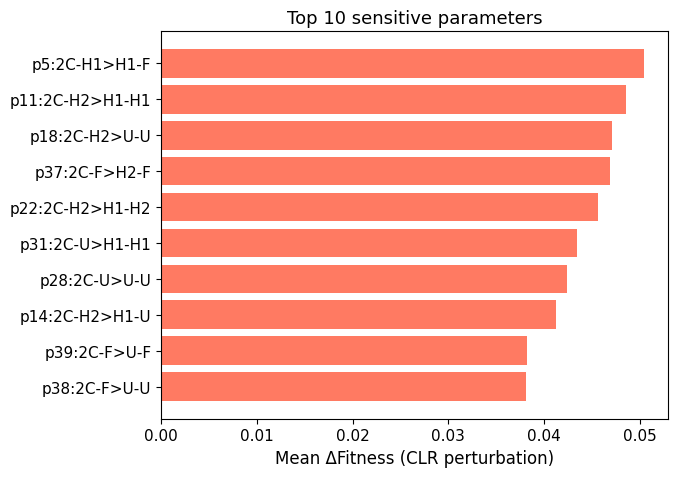

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# 新的敏感性数据
labels = ['p5:2C-H1>H1-F','p11:2C-H2>H1-H1','p18:2C-H2>U-U','p37:2C-F>H2-F','p22:2C-H2>H1-H2','p31:2C-U>H1-H1','p28:2C-U>U-U','p14:2C-H2>H1-U','p39:2C-F>U-F','p38:2C-F>U-U']
mean_deltas = [0.050427, 0.048593, 0.047093, 0.046927, 0.045593,
               0.043427, 0.042427, 0.041260, 0.038260, 0.038093]

plt.figure(figsize=(7,5))
plt.barh(labels[::-1], np.array(mean_deltas[::-1]), 
         color='tomato', alpha=0.85)

plt.xlabel('Mean ΔFitness (CLR perturbation)', fontsize=12)
plt.title('Top 10 sensitive parameters', fontsize=13)
plt.tick_params(axis='both', labelsize=11)
plt.tight_layout()
plt.savefig('figure2d_top_sensitivity_mean_only.png', dpi=300)
plt.show()


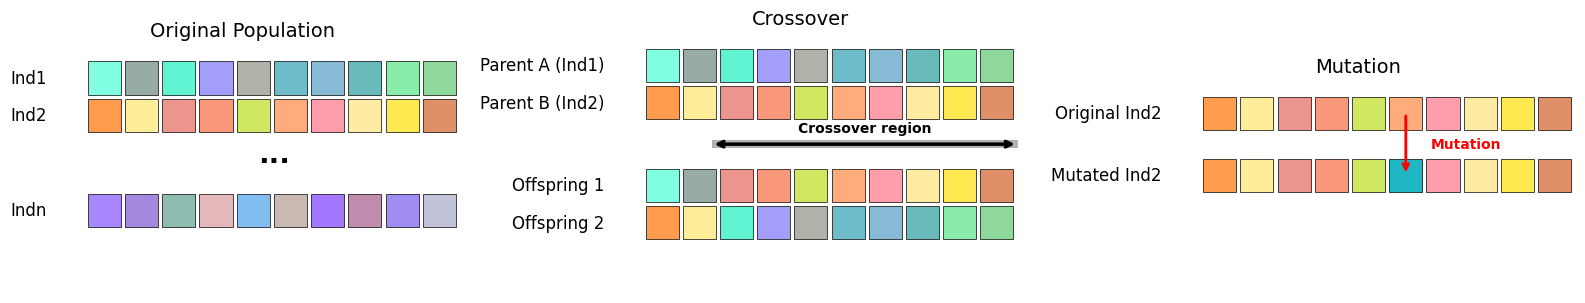

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ---------- 参数 ----------
n_genes = 10
cell_size = 0.8
gap = 0.1
y_step = cell_size + gap

individual_base_colors = ['#8ECFC9', '#FFBE7A', '#B39DDB']  # Ind1, Ind2, Indn

np.random.seed(42)
colors = []
for i in range(3):
    ind_colors = []
    for j in range(n_genes):
        base = individual_base_colors[i]
        r = int(base[1:3], 16) / 255.0
        g = int(base[3:5], 16) / 255.0
        b = int(base[5:7], 16) / 255.0
        r_offset = np.random.uniform(-0.2, 0.2)
        g_offset = np.random.uniform(-0.2, 0.2)
        b_offset = np.random.uniform(-0.2, 0.2)
        r = np.clip(r + r_offset, 0, 1)
        g = np.clip(g + g_offset, 0, 1)
        b = np.clip(b + b_offset, 0, 1)
        ind_colors.append((r, g, b))
    colors.append(ind_colors)

def draw_individual(ax, y, colors_row, label=""):
    for x in range(n_genes):
        rect = patches.Rectangle((x * (cell_size + gap), y), cell_size, cell_size,
                                 facecolor=colors_row[x], edgecolor='black', linewidth=0.5)
        ax.add_patch(rect)
    if label:
        ax.text(-1, y + cell_size/2, label, ha='right', va='center', fontsize=12)

# 创建画布，增加高度并预留底部空间
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.subplots_adjust(wspace=0.35, bottom=0.15)  # 增大底部边距

# ----- 子图1：原始种群（Ind1, Ind2, ..., Indn）-----
ax1 = axes[0]
y_start = 2.0

# 绘制 Ind1, Ind2
draw_individual(ax1, y_start, colors[0], label="Ind1")
draw_individual(ax1, y_start - y_step, colors[1], label="Ind2")

# 省略号（上移）
ellipsis_y = y_start - 1.6 * y_step
ax1.text(n_genes * (cell_size + gap) / 2, ellipsis_y, "...",
         ha='center', va='center', fontsize=20, fontweight='bold')

# Indn 位置（下移一点，避免与省略号重叠）
indn_y = y_start - 3 * y_step -0.5
draw_individual(ax1, indn_y, colors[2], label="Indn")

# 计算最低 y 并设置 ylim
lowest_y = indn_y - cell_size  # 个体最低点是方块底部
ax1.set_ylim(lowest_y - 0.5, y_start + y_step + 0.3)
ax1.set_xlim(-1.5, n_genes * (cell_size + gap))
ax1.set_aspect('equal')
ax1.set_title("Original Population", fontsize=14)
ax1.axis('off')

# ----- 子图2：交叉操作（父母在上，子女在下）-----
ax2 = axes[1]
parent1 = colors[0]  # Ind1
parent2 = colors[1]  # Ind2
crossover_point = 2
offspring1 = parent1[:crossover_point] + parent2[crossover_point:]
offspring2 = parent2[:crossover_point] + parent1[crossover_point:]

parent_y_start = 2.0
draw_individual(ax2, parent_y_start, parent1, label="Parent A (Ind1)")
draw_individual(ax2, parent_y_start - y_step, parent2, label="Parent B (Ind2)")

# 交叉指示条
cross_start = crossover_point * (cell_size + gap) - 0.2
cross_end = n_genes * (cell_size + gap)
mid_y = parent_y_start - 2 * y_step + 0.3
ax2.add_patch(patches.Rectangle((cross_start, mid_y - 0.1),
                                 cross_end - cross_start, 0.2,
                                 facecolor='gray', alpha=0.6, edgecolor='none'))
ax2.annotate('', xy=(cross_end, mid_y), xytext=(cross_start, mid_y),
             arrowprops=dict(arrowstyle='<->', color='black', lw=2.5))
ax2.text((cross_start + cross_end)/2, mid_y + 0.3, "Crossover region",
         ha='center', fontsize=10, weight='bold')

# 子女
offspring_y_start = parent_y_start - 3 * y_step - 0.2
draw_individual(ax2, offspring_y_start, offspring1, label="Offspring 1")
draw_individual(ax2, offspring_y_start - y_step, offspring2, label="Offspring 2")

lowest_y2 = offspring_y_start - y_step - cell_size
ax2.set_ylim(lowest_y2 - 0.5, parent_y_start + y_step + 0.3)
ax2.set_xlim(-1.5, n_genes * (cell_size + gap))
ax2.set_aspect('equal')
ax2.set_title("Crossover", fontsize=14)
ax2.axis('off')

# ----- 子图3：变异操作（使用 Ind2）-----
ax3 = axes[2]
original_mutant = colors[1]  # Ind2
mutant = original_mutant.copy()
mutate_pos = 5
new_color = np.random.rand(3)
while np.allclose(new_color, mutant[mutate_pos]):
    new_color = np.random.rand(3)
mutant[mutate_pos] = new_color

draw_individual(ax3, 2.0, original_mutant, label="Original Ind2")

x_center = mutate_pos * (cell_size + gap) + cell_size/2
y_orig = 2.0 + cell_size/2
y_mut = 0.5 + cell_size/2
ax3.annotate('', xy=(x_center, y_mut), xytext=(x_center, y_orig),
             arrowprops=dict(arrowstyle='->', color='red', lw=2))
ax3.text(x_center + 0.6, (y_orig + y_mut)/2, "Mutation",
         ha='left', va='center', fontsize=10, color='red', weight='bold')

draw_individual(ax3, 0.5, mutant, label="Mutated Ind2")

lowest_y3 = 0.5 - cell_size
ax3.set_ylim(lowest_y3 - 0.5, 2.0 + y_step + 0.3)
ax3.set_xlim(-1.5, n_genes * (cell_size + gap))
ax3.set_aspect('equal')
ax3.set_title("Mutation", fontsize=14)
ax3.axis('off')

plt.tight_layout()
plt.savefig("GA_schematic_full.png", dpi=200, bbox_inches='tight')
plt.show()